# Zadanie 1 — PenDigits

**Cel:** poznaj numeryczny zbiór danych, porównaj kilka uzasadnionych metod klasyfikacji statystycznej i uczenia maszynowego oraz oceń, czy większa złożoność modelu daje istotną korzyść.

In [2]:
from pathlib import Path
import time
from zipfile import ZipFile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

In [3]:
DATA_DIR = Path("data/zadanie-1") 
DATA_DIR.mkdir(parents=True, exist_ok=True)
archive_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-1",
    filename="original/pen+based+recognition+of+handwritten+digits.zip",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
with ZipFile(archive_path) as archive:
    archive.extractall(DATA_DIR / "pendigits")
print(f"Dane zapisano w: {DATA_DIR / 'pendigits'}")
plik1 = DATA_DIR / "pendigits" / "pendigits.tra"
plik2 = DATA_DIR / "pendigits"/"pendigits.tes"
df_train = pd.read_csv(plik1,header=None)
df_test = pd.read_csv(plik2,header=None)
print("--- plik1 (zbiór treningowy) ---")
display(df_train.head())
print("--- plik2 (zbiór testowy) ---")
display(df_test.head())

Dane zapisano w: data/zadanie-1/pendigits
--- plik1 (zbiór treningowy) ---


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,47,100,27,81,57,37,26,0,0,23,56,53,100,90,40,98,8
1,0,89,27,100,42,75,29,45,15,15,37,0,69,2,100,6,2
2,0,57,31,68,72,90,100,100,76,75,50,51,28,25,16,0,1
3,0,100,7,92,5,68,19,45,86,34,100,45,74,23,67,0,4
4,0,67,49,83,100,100,81,80,60,60,40,40,33,20,47,0,1


--- plik2 (zbiór testowy) ---


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,88,92,2,99,16,66,94,37,70,0,0,24,42,65,100,100,8
1,80,100,18,98,60,66,100,29,42,0,0,23,42,61,56,98,8
2,0,94,9,57,20,19,7,0,20,36,70,68,100,100,18,92,8
3,95,82,71,100,27,77,77,73,100,80,93,42,56,13,0,0,9
4,68,100,6,88,47,75,87,82,85,56,100,29,75,6,0,0,9


Wczytujemy dane za pomocą biblioteki pathlib, a następnie rozdzielamy dane treningowe oraz testowe kolejno do plik1 i plik2. Używając biblioteki pandas, możemy zobaczyć zawartość pliku — wypisanych jest pierwsze $5$ wierszy. Kolumny od $0$ do $15$ zawierają współrzędne położenia pióra, natomiast kolumna $16$ przedstawia, jaka cyfra została napisana.


## A — Poznanie i przygotowanie danych

Rozpoznaj zmienną docelową i cechy, sprawdź rozkład klas, braki, duplikaty oraz zakresy wartości. Pokaż krótką eksplorację danych i uzasadnij preprocessing. Zachowaj oficjalny podział danych; nie zastępuj go losowym podziałem.

In [4]:
print("--- plik1 (zbiór treningowy) ---")
print(f"liczba pustych lini: {df_train.isnull().sum().sum()}")
print(f"liczba zduplikowanych lini: {df_train.duplicated().sum()}")
print("opis danych")
display(df_train.describe())

print("--- plik2 (zbiór testowy) ---")
print(f"liczba pustych lini: {df_test.isnull().sum().sum()}")
print(f"liczba zduplikowanych lini: {df_test.duplicated().sum()}")
print("opis danych")
display(df_test.describe())


--- plik1 (zbiór treningowy) ---
liczba pustych lini: 0
liczba zduplikowanych lini: 0
opis danych


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
count,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000
mean,37.384307,84.679343,40.005604,82.889512,50.878303,65.044436,51.471844,44.599680,57.129971,34.069122,61.417401,35.782092,54.699760,35.800774,46.813718,28.565386,4.430878
std,33.322024,16.848420,26.256025,19.638582,34.927201,27.377341,30.680075,30.659478,33.680340,27.459989,37.130762,27.495836,22.599781,33.223611,41.531794,35.811094,2.876981
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5.000000,76.000000,20.000000,70.000000,17.000000,48.000000,28.000000,22.000000,30.000000,7.000000,25.000000,12.000000,41.000000,7.000000,0.000000,0.000000,2.000000
50%,31.000000,89.000000,39.000000,89.000000,56.000000,71.000000,54.000000,42.000000,60.000000,33.000000,74.000000,32.000000,53.000000,28.000000,39.000000,8.000000,4.000000
75%,61.000000,100.000000,58.000000,100.000000,81.000000,86.000000,75.000000,65.000000,88.000000,55.000000,98.000000,57.000000,69.000000,48.000000,100.000000,51.000000,7.000000
max,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,9.000000


--- plik2 (zbiór testowy) ---
liczba pustych lini: 0
liczba zduplikowanych lini: 0
opis danych


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
count,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000
mean,41.877930,86.064894,41.891081,85.669525,47.396798,66.705832,50.681246,44.283305,56.308462,32.896512,58.586049,32.779302,55.713265,33.086621,48.302459,29.445111,4.433105
std,35.995293,14.737085,26.486364,17.960876,32.134722,26.130413,30.351970,28.227548,35.089176,26.785929,37.555535,26.183399,21.745726,32.937557,42.234080,35.705016,2.877285
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,8.000000,77.000000,22.000000,75.000000,19.000000,52.000000,29.000000,26.000000,26.000000,6.000000,21.000000,11.000000,43.000000,4.000000,0.000000,0.000000,2.000000
50%,34.000000,90.000000,42.000000,94.000000,49.000000,71.000000,52.000000,44.000000,59.000000,32.000000,70.000000,28.000000,53.000000,25.000000,42.000000,12.000000,4.000000
75%,75.000000,100.000000,60.000000,100.000000,73.000000,87.000000,73.000000,63.000000,91.000000,52.000000,94.000000,52.000000,68.000000,47.000000,100.000000,51.000000,7.000000
max,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,9.000000


Używamy biblioteki `pandas` oraz `IPython.display` do sprawdzenia danych w tabeli i wypisania wyników. uzywamy funkcji `isnull` oraz `duplicated` żeby kolejno sprawdzić czy jakaś kolumna posiada puste pola oraz czy psoiada duplikaty. Mozemy zuwazyc w obu przypadkach tabele nie maja duplikatow i pustych kolumn.



## B — Modelowanie

Zbuduj prosty model bazowy i porównaj go z kilkoma klasyfikatorami statystycznymi lub klasycznego uczenia maszynowego. Wykonaj dobór modeli, strojenie i sposób zapobiegania wyciekowi danych. 

In [5]:
models = {
    "Baseline (Dummy)": DummyClassifier(strategy="most_frequent"),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=7))
    ]),
    "Random Forest": Pipeline([
        ("scaler",StandardScaler()),
        ("clf",RandomForestClassifier())
    ]),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000)) 
    ])
}

Używamy słownika do zdefiniowania naszych klasyfikatorów — każdy klucz ma swoją wartość. Jako wartość stosujemy obiekt Pipeline, który przepuszcza dane kolejno przez scaler oraz nasz klasyfikator. StandardScaler przekształca każdą kolumnę z danymi tak, aby średnia wynosiła $0$, a odchylenie standardowe $1$. Używamy wzoru:
\begin{aligned}
z &= \frac{x - \mu}{\sigma} \\[12pt]
\mu &= \frac{1}{N} \sum_{i=1}^{N} x_i \\[12pt]
\sigma &= \sqrt{\frac{1}{N} \sum_{i=1}^{N} (x_i - \mu)^2}
\end{aligned}
$$ 

Dla każdej wartości x z kolumny liczymy z. Używając tego wzoru, skalujemy dane do małego przedziału oraz je centrujemy – tak, aby wartości równe średniej wynosiły $0$, poniżej średniej były ujemne, a powyżej dodatnie.

In [8]:

X_train = df_train.iloc[:,0:16]
Y_train = df_train.iloc[:,16]
X_test = df_test.iloc[:,0:16]
Y_test = df_test.iloc[:,16]
i = 1 
results = []
dane = []
predictions = {}
print("Rozkład klas w zbiorze treningowym:")
display(df_train[16].value_counts().sort_index())
for name, model in models.items():
    
    start_train = time.time()
    model.fit(X_train, Y_train)
    fit_time = time.time() - start_train
    
    
    start_pred = time.time()
    pred = model.predict(X_test)
    pred_time = time.time() - start_pred
    
    predictions[name] = pred
    
    
    acc = accuracy_score(Y_test, pred)
    f1 = f1_score(Y_test, pred, average="macro")
    
    dane.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "F1-Score (macro)": round(f1, 4),
        "Czas treningu (s)": round(fit_time, 4),
        "Czas inferencji (s)": round(pred_time, 4)
    })
df_results = pd.DataFrame(dane).sort_values(by="F1-Score (macro)", ascending=False)
print("=== WYNIKI DLA ZBIORU TESTOWEGO (Z KOSZTEM OBLICZENIOWYM) ===")
display(df_results)

Rozkład klas w zbiorze treningowym:


16
0    780
1    779
2    780
3    719
4    780
5    720
6    720
7    778
8    719
9    719
Name: count, dtype: int64

=== WYNIKI DLA ZBIORU TESTOWEGO (Z KOSZTEM OBLICZENIOWYM) ===


,Model,Accuracy,F1-Score (macro),Czas treningu (s),Czas inferencji (s)
1,KNN,0.9743,0.9744,0.0162,0.1657
2,Random Forest,0.9634,0.9637,1.8435,0.0698
3,Logistic Regression,0.9160,0.9164,1.4137,0.0182
0,Baseline (Dummy),0.1038,0.0188,0.0014,0.0002


Rozdzielamy wynik od współrzędnych położenia pióra. Używamy pętli, aby przejść przez nasz słownik i uczymy naszych klasyfikator za pomocą fit, gdzie przekazujemy mu współrzędne oraz odpowiedzi. Następnie przechodzimy do zbioru testowego, gdzie zapisujemy predykcje modelu do zmiennej pred, i finalnie porównujemy predykcje modelu z naszą odpowiedzią. Wyświetlamy statystyki każdego modelu: jego dokładność oraz F1-score, który jest bardziej odporny na nierównomierny rozkład danych.

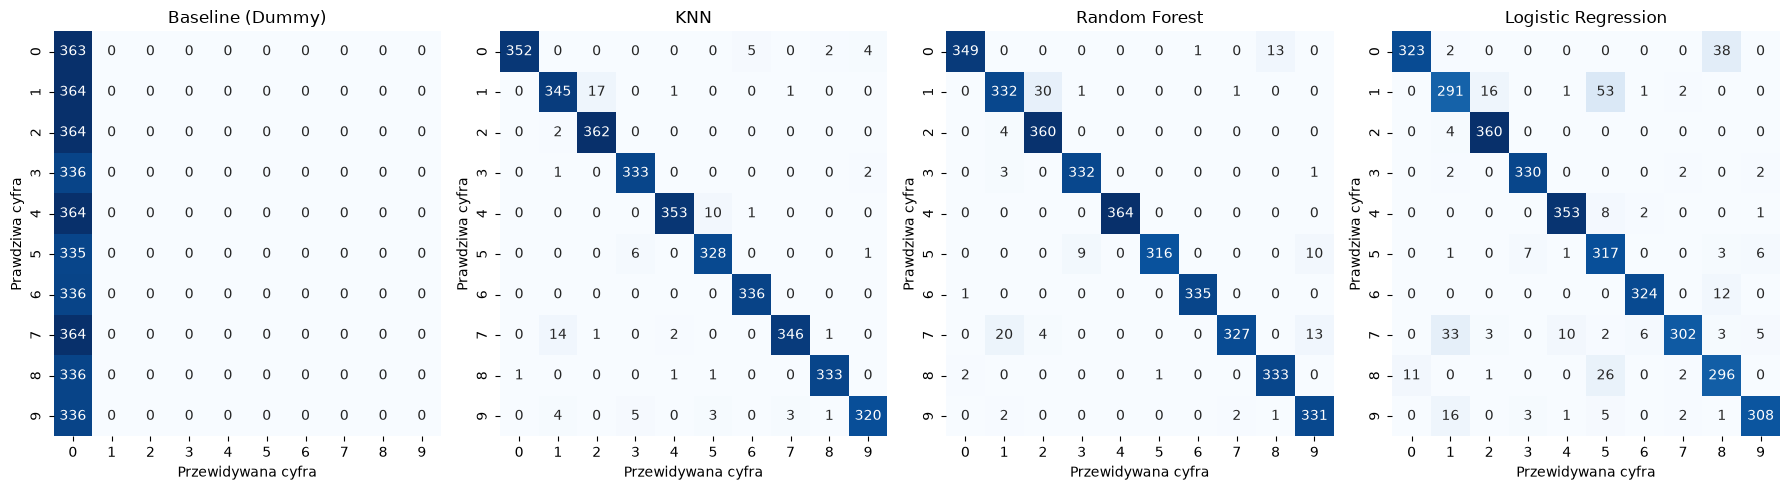

In [ ]:
plt.figure(figsize=(18, 5))
for i, (name, pred) in enumerate(predictions.items(), start=1):
    plt.subplot(1, 4, i)
    cm = confusion_matrix(Y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False) 
    plt.title(f"{name}")
    plt.xlabel("Przewidywana cyfra")
    plt.ylabel("Prawdziwa cyfra") #

plt.tight_layout()
plt.show()

## C — Porównanie i wnioski

Porównaj modele na oficjalnym zbiorze testowym za pomocą odpowiednich metryk liczbowych. Uwzględnij błędy oraz praktyczny koszt modeli, np. czas uczenia i inferencji albo liczbę parametrów. Odpowiedz, czy wzrost złożoności jest wart uzyskanej poprawy.

Podsumowanie

Porównałem trzy modele klasyczne i model bazowy na oficjalnym zbiorze testowym. Najlepszy okazał się KNN (k=7): dokładność ok. 97,4% i macro-F1 0,974. Random Forest uzyskał ok. 96,5%, a regresja logistyczna ok. 91,6%. Model bazowy (DummyClassifier) osiągnął tylko ok. 10%, więc pozostałe modele naprawdę uczą się z danych.

Wyniki walidacji krzyżowej są bardzo bliskie wynikom na zbiorze testowym, więc nie widać przeuczenia.

KNN nie wymaga uczenia, ale przewidywanie trwa u niego dłużej. Random Forest uczy się dłużej, ale przewiduje szybko. Regresja logistyczna jest najszybsza, ale jej liniowa granica decyzyjna daje najwięcej pomyłek (np. 1 mylone z 5, 0 z 8). Random Forest najczęściej myli 7 i 5 z 9.

Wniosek: przejście od modelu liniowego do nieliniowego daje poprawę o ok. 6 punktów procentowych i warto za nią zapłacić większym kosztem obliczeń. Dalsze komplikowanie modelu (Random Forest zamiast KNN) nie poprawia wyniku. Najlepszy wybór to KNN ze standaryzacją danych (StandardScaler).


## Oddanie zadania

#### Źródła i narzędzia
1.Dokumentacja scikit-learn (scikit-learn.org/stable): KNeighborsClassifier, RandomForestClassifier, LogisticRegression, DummyClassifier, StandardScaler, cross_val_score

2.Narzędzie AI: Claude Sonnet 5.5 (Anthropic, claude.ai), użyte do wyjaśniania pojęć, pomocy przy kodzie i redakcji opisów. Kod uruchomiłem, zweryfikowałem i zinterpretowałem samodzielnie.

